# ¿Se paga igual por el mismo trabajo?

Análisis de equidad salarial de una embotelladora **ficticia**: foto al 30/09/2026 de 520 colaboradores activos, con montos en bolivianos (Bs).

**Respuesta corta: en la mayoría de los niveles, sí; en Técnico y supervisión, no.**

- En promedio, las mujeres ganan **13,4%** menos que los hombres (7,4% en la mediana).
- La mayor parte de esa diferencia se explica porque mujeres y hombres trabajan en cargos distintos: según Oaxaca-Blinder, el 70% se explica por cargo, antigüedad y desempeño (el cargo solo, 58%). Al comparar el mismo cargo, antigüedad y desempeño, la brecha baja a **3,2%** (IC 95%: 1,5% a 4,8%).
- Esa brecha no explicada se concentra en **Técnico y supervisión**: ahí llega a **11,7%**. En los otros niveles no se distingue de cero.
- Además, 33 personas ganan menos que el mínimo de su banda y hay **compresión** en 3 cargos operativos: quien entró este año gana más que quien tiene 3 a 5 años.
- Cerrar las tres brechas cuesta **Bs 1.008.264 al año**. Lo primero: revisar a las mujeres de Técnico y supervisión (Bs 456.036 al año).

> Los datos se generan con `generar_datos.py` (semilla fija, así que los resultados se reproducen). Los números ilustran el método: no describen a ninguna empresa real. Una brecha no explicada no prueba discriminación, pero obliga a revisar caso por caso.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.oaxaca import OaxacaBlinder

import graficos as g

g.aplicar_estilo()
pd.set_option("display.float_format", lambda x: g.miles(x, 0) if abs(x) >= 100 else g.miles(x, 2))
pd.set_option("display.max_colwidth", 60)

DATOS, IMG, RESULTADOS = Path("datos"), Path("img"), Path("resultados")
IMG.mkdir(exist_ok=True)
RESULTADOS.mkdir(exist_ok=True)
FECHA_CORTE = pd.Timestamp("2026-09-30")
NIVELES = ["Operativo", "Técnico y supervisión", "Profesional y jefatura"]

colaboradores = pd.read_csv(DATOS / "colaboradores.csv", parse_dates=["fecha_ingreso"])
bandas = pd.read_csv(DATOS / "bandas.csv")
print(f"{len(colaboradores)} colaboradores activos al {FECHA_CORTE:%d/%m/%Y} | {len(bandas)} cargos con banda salarial")
colaboradores.head()

520 colaboradores activos al 30/09/2026 | 31 cargos con banda salarial


,id_colaborador,area,cargo,nivel,genero,fecha_ingreso,evaluacion_desempeno,haber_basico_bs
0,C0001,Logística y Distribución,Chofer repartidor,Operativo,Hombre,1996-09-30,4,5480
1,C0002,Producción,Operario de línea,Operativo,Mujer,1997-07-09,3,4350
2,C0003,Logística y Distribución,Ayudante de reparto,Operativo,Hombre,1999-01-06,3,3655
3,C0004,Calidad,Inspector de calidad,Operativo,Mujer,2000-03-12,3,4113
4,C0005,Producción,Operador de llenadora,Operativo,Hombre,2001-02-10,3,5089


## 1. Los datos

- `colaboradores.csv`: una fila por persona activa al 30/09/2026, con área, cargo, nivel, género, fecha de ingreso, última evaluación de desempeño (1 a 5) y haber básico mensual en Bs.
- `bandas.csv`: la banda salarial de cada cargo, con mínimo, punto medio y máximo.

Se calculan tres variables: la **antigüedad** en años, **mujer** (1 = mujer, 0 = hombre) y el **logaritmo del haber**. El logaritmo permite leer las diferencias de la regresión como porcentajes.

In [2]:
datos = colaboradores.merge(bandas[["cargo", "minimo_bs", "punto_medio_bs", "maximo_bs"]], on="cargo", how="left")
datos["antiguedad"] = (FECHA_CORTE - datos["fecha_ingreso"]).dt.days / 365.25
datos["mujer"] = (datos["genero"] == "Mujer").astype(int)
datos["log_haber"] = np.log(datos["haber_basico_bs"])

def composicion(columna, orden=None):
    tabla = pd.crosstab(datos[columna], datos["genero"])
    tabla["% mujeres"] = (tabla["Mujer"] / tabla.sum(axis=1)).map(g.porcentaje)
    return tabla.reindex(orden) if orden else tabla.sort_values("Mujer")

antiguedad = datos.groupby("genero")["antiguedad"].mean()
print(f"Mujeres: {datos['mujer'].sum()} de {len(datos)} ({g.porcentaje(datos['mujer'].mean(), 1)})")
print(f"Antigüedad promedio: mujeres {g.miles(antiguedad['Mujer'], 1)} años, hombres {g.miles(antiguedad['Hombre'], 1)} años")
composicion("area")

Mujeres: 165 de 520 (31,7%)
Antigüedad promedio: mujeres 4,2 años, hombres 5,2 años


genero,Hombre,Mujer,% mujeres
area,,,
Mantenimiento,39,3,7%
Logística y Distribución,111,12,10%
Calidad,10,21,68%
Administración y Finanzas,11,32,74%
Ventas,36,37,51%
Producción,148,60,29%


In [3]:
composicion("nivel", NIVELES)

genero,Hombre,Mujer,% mujeres
nivel,,,
Operativo,263,119,31%
Técnico y supervisión,66,37,36%
Profesional y jefatura,26,9,26%


Producción, Logística y Mantenimiento tienen mayoría de hombres; Administración y Calidad, de mujeres; Ventas está repartida. Esta mezcla importa: si mujeres y hombres trabajan en cargos distintos, sus sueldos promedio también son distintos, aunque cada cargo pague igual.

## 2. Brecha bruta

**Brecha** = cuánto menos gana una mujer que un hombre, en % del sueldo del hombre: (hombres − mujeres) / hombres. Se calcula con el promedio y con la mediana (el sueldo del medio: la mitad gana menos y la otra mitad, más).

In [4]:
por_genero = datos.groupby("genero")["haber_basico_bs"].agg(personas="count", promedio="mean", mediana="median")
brecha_media = 1 - por_genero.loc["Mujer", "promedio"] / por_genero.loc["Hombre", "promedio"]
brecha_mediana = 1 - por_genero.loc["Mujer", "mediana"] / por_genero.loc["Hombre", "mediana"]
print(f"Brecha bruta en el promedio: {g.porcentaje(brecha_media, 1)}")
print(f"Brecha bruta en la mediana: {g.porcentaje(brecha_mediana, 1)}")
por_genero

Brecha bruta en el promedio: 13,4%
Brecha bruta en la mediana: 7,4%


,personas,promedio,mediana
genero,,,
Hombre,355,5.439,4.314
Mujer,165,4.712,3.996


In [5]:
por_nivel_bruto = datos.pivot_table(index="nivel", columns="genero", values="haber_basico_bs", aggfunc="mean").reindex(NIVELES)
por_nivel_bruto["brecha bruta"] = (1 - por_nivel_bruto["Mujer"] / por_nivel_bruto["Hombre"]).map(lambda v: g.porcentaje(v, 1))
por_nivel_bruto["% mujeres"] = composicion("nivel", NIVELES)["% mujeres"]
por_nivel_bruto

genero,Hombre,Mujer,brecha bruta,% mujeres
nivel,,,,
Operativo,4.092,3.802,"7,1%",31%
Técnico y supervisión,7.376,5.925,"19,7%",36%
Profesional y jefatura,14.152,11.769,"16,8%",26%


La brecha en la mediana es menor que en el promedio: el promedio de los hombres sube por los sueldos de las jefaturas, que ocupan sobre todo hombres. Dentro de cada nivel también hay brecha bruta, en parte porque las mujeres están más en los cargos peor pagados de cada nivel (mercaderistas, auxiliares, asistentes).

La brecha bruta mezcla dos cosas distintas: **dónde** trabajan mujeres y hombres, y **cuánto** se les paga por el mismo trabajo. Las siguientes secciones las separan.

## 3. Brecha ajustada: el mismo trabajo

Una regresión compara a una mujer y a un hombre con el **mismo cargo**, la **misma antigüedad** y el **mismo desempeño**:

`log(haber) = mujer + cargo + antigüedad + antigüedad² + desempeño`

- El coeficiente de *mujer* dice cuánto cambia el haber por ser mujer, con todo lo demás igual. Como el haber está en logaritmo, la brecha en % es 1 − e<sup>coeficiente</sup>.
- La antigüedad entra también al cuadrado, porque el sueldo sube más en los primeros años que después.
- Los errores estándar son robustos (HC3): no suponen que la variación de los sueldos sea igual en todos los cargos.
- Un cargo con una sola persona no permite comparar dentro del cargo, así que queda fuera de las regresiones.

Se estiman tres versiones, de menos a más controles, para ver cuánto baja la brecha en cada paso.

In [6]:
tamano_cargo = datos.groupby("cargo")["id_colaborador"].transform("count")
muestra = datos[tamano_cargo >= 2].copy()
print("Cargos con una sola persona (fuera de las regresiones):", ", ".join(sorted(datos.loc[tamano_cargo < 2, "cargo"])))
print(f"Personas en la comparación: {len(muestra)} ({muestra['mujer'].sum()} mujeres)")

CONTROLES = "C(cargo) + antiguedad + I(antiguedad ** 2) + evaluacion_desempeno"
FORMULAS = {
    "Sin controles": "log_haber ~ mujer",
    "Mismo cargo": "log_haber ~ mujer + C(cargo)",
    "Mismo cargo, antigüedad y desempeño": f"log_haber ~ mujer + {CONTROLES}",
}

def brecha(resultado, termino="mujer"):
    """Brecha en %: cuánto menos gana una mujer que un hombre comparable (positivo = gana menos)."""
    inferior, superior = resultado.conf_int().loc[termino]
    return pd.Series({"brecha": 1 - np.exp(resultado.params[termino]),
                      "ic95_desde": 1 - np.exp(superior), "ic95_hasta": 1 - np.exp(inferior),
                      "p_valor": resultado.pvalues[termino]})

def en_porcentaje(tabla):
    """Formato de lectura: brechas en %, p-valor con 3 decimales."""
    t = tabla.copy()
    for columna in ["brecha", "ic95_desde", "ic95_hasta"]:
        t[columna] = t[columna].map(lambda v: g.porcentaje(v, 1))
    t["p_valor"] = t["p_valor"].map(lambda p: "< 0,001" if p < 0.001 else g.miles(p, 3))
    return t

modelos = {nombre: smf.ols(formula, data=muestra).fit(cov_type="HC3") for nombre, formula in FORMULAS.items()}
escalera = pd.DataFrame({nombre: brecha(resultado) for nombre, resultado in modelos.items()}).T
en_porcentaje(escalera)

Cargos con una sola persona (fuera de las regresiones): Jefe comercial
Personas en la comparación: 519 (165 mujeres)


,brecha,ic95_desde,ic95_hasta,p_valor
Sin controles,"10,3%","4,4%","15,9%","< 0,001"
Mismo cargo,"4,9%","2,8%","7,0%","< 0,001"
"Mismo cargo, antigüedad y desempeño","3,2%","1,5%","4,8%","< 0,001"


In [7]:
ajustado = modelos["Mismo cargo, antigüedad y desempeño"]
brecha_ajustada = escalera.loc["Mismo cargo, antigüedad y desempeño"]
cinco_anios = np.exp(5 * ajustado.params["antiguedad"] + 25 * ajustado.params["I(antiguedad ** 2)"]) - 1
print(f"Brecha ajustada: {g.porcentaje(brecha_ajustada['brecha'], 1)} "
      f"(IC 95%: {g.porcentaje(brecha_ajustada['ic95_desde'], 1)} a {g.porcentaje(brecha_ajustada['ic95_hasta'], 1)})")
print(f"Con 5 años de antigüedad, el haber es {g.porcentaje(cinco_anios, 1)} más alto que al ingresar")
print(f"Cada punto más en la evaluación de desempeño suma {g.porcentaje(np.exp(ajustado.params['evaluacion_desempeno']) - 1, 1)} al haber")
print(f"R²: {g.miles(ajustado.rsquared, 2)} | personas: {int(ajustado.nobs)}")

Brecha ajustada: 3,2% (IC 95%: 1,5% a 4,8%)
Con 5 años de antigüedad, el haber es 8,8% más alto que al ingresar
Cada punto más en la evaluación de desempeño suma 2,3% al haber
R²: 0,97 | personas: 519


En logaritmos, la brecha sin controles es más chica que la del promedio simple: el logaritmo pesa menos los sueldos más altos. Al comparar el mismo cargo, la brecha cae a menos de la mitad. Lo que queda después de sumar antigüedad y desempeño es la **brecha no explicada**: no se debe al cargo, a la antigüedad ni al desempeño.

Una brecha no explicada **no prueba discriminación**. Puede haber razones que estos datos no miden: experiencia previa, formación, turnos, una negociación al ingresar. Pero sí obliga a revisar caso por caso.

PosixPath('img/01_brecha_bruta_vs_ajustada.png')

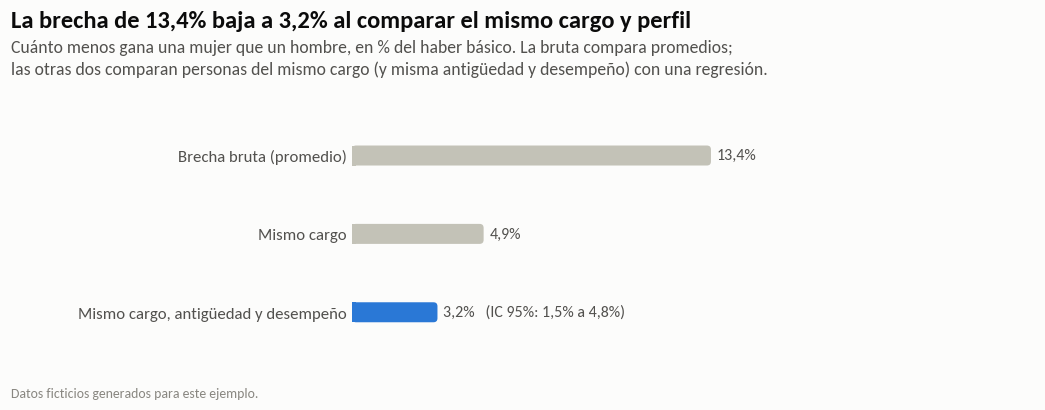

In [8]:
pasos = pd.Series({
    "Brecha bruta (promedio)": brecha_media,
    "Mismo cargo": escalera.loc["Mismo cargo", "brecha"],
    "Mismo cargo, antigüedad y desempeño": brecha_ajustada["brecha"],
})
textos = [g.porcentaje(v, 1) for v in pasos.values]
textos[-1] += f"   (IC 95%: {g.porcentaje(brecha_ajustada['ic95_desde'], 1)} a {g.porcentaje(brecha_ajustada['ic95_hasta'], 1)})"

fig, ax = g.figura(alto=3.8, ejes=(0.33, 0.12, 0.62, 0.6))
g.encabezado(fig, f"La brecha de {g.porcentaje(brecha_media, 1)} baja a {g.porcentaje(brecha_ajustada['brecha'], 1)} "
                  "al comparar el mismo cargo y perfil",
             "Cuánto menos gana una mujer que un hombre, en % del haber básico. La bruta compara promedios;\n"
             "las otras dos comparan personas del mismo cargo (y misma antigüedad y desempeño) con una regresión.")
g.barras_horizontales(ax, pasos.index, pasos.values, [g.GRIS, g.GRIS, g.AZUL], textos=textos,
                      x_max=pasos.max() * 1.9, grosor_px=20)
g.pie(fig)
g.guardar(fig, IMG / "01_brecha_bruta_vs_ajustada.png")

## 4. Descomposición de Oaxaca-Blinder

Divide la brecha (en logaritmos) en dos partes:

- **Explicada**: la parte que se debe a que mujeres y hombres tienen distinto cargo, antigüedad y desempeño. Se valora con los mismos "precios" para todos: los coeficientes del modelo conjunto.
- **No explicada**: la parte que se debe a que a mujeres y hombres se les paga distinto por las mismas características.

Como referencia se usa el modelo conjunto con la variable *mujer* incluida (la opción `pooled` de statsmodels). Con esa referencia, la parte no explicada es igual al coeficiente de *mujer* de la sección anterior. El cálculo se hace a mano para separar la parte explicada en cargo, antigüedad y desempeño, y después se controla con `OaxacaBlinder`.

In [9]:
X = pd.get_dummies(muestra["cargo"], prefix="cargo", drop_first=True, dtype=float)
X["antiguedad"] = muestra["antiguedad"]
X["antiguedad2"] = muestra["antiguedad"] ** 2
X["desempeno"] = muestra["evaluacion_desempeno"].astype(float)
X = sm.add_constant(X)
X["mujer"] = muestra["mujer"].astype(float)
y = muestra["log_haber"]
es_mujer = muestra["mujer"] == 1

conjunto = sm.OLS(y, X).fit()
precios = conjunto.params.drop("mujer")
diferencia = (X[~es_mujer].mean() - X[es_mujer].mean()).drop("mujer")
aporte = diferencia * precios
brecha_log = y[~es_mujer].mean() - y[es_mujer].mean()

partes = pd.Series({
    "Explicada por el cargo": aporte.filter(like="cargo_").sum(),
    "Explicada por la antigüedad": aporte[["antiguedad", "antiguedad2"]].sum(),
    "Explicada por el desempeño": aporte["desempeno"],
})
partes["No explicada"] = brecha_log - partes.sum()
oaxaca = pd.DataFrame({"puntos (log × 100)": partes * 100,
                       "% de la brecha": (partes / brecha_log).map(lambda v: g.porcentaje(v, 1))})
explicada = 1 - partes["No explicada"] / brecha_log
print(f"Brecha en logaritmos: {g.miles(brecha_log * 100, 1)} puntos")
print(f"Parte explicada: {g.porcentaje(explicada)} (el cargo solo: {g.porcentaje(partes['Explicada por el cargo'] / brecha_log)})")
print(f"Parte no explicada: {g.miles(partes['No explicada'] * 100, 1)} puntos = coeficiente de mujer "
      f"({g.miles(-conjunto.params['mujer'] * 100, 1)})")
oaxaca

Brecha en logaritmos: 10,9 puntos
Parte explicada: 70% (el cargo solo: 58%)
Parte no explicada: 3,2 puntos = coeficiente de mujer (3,2)


,puntos (log × 100),% de la brecha
Explicada por el cargo,"6,29","57,6%"
Explicada por la antigüedad,"1,39","12,7%"
Explicada por el desempeño,"0,00","0,0%"
No explicada,"3,23","29,6%"


In [10]:
# Control con statsmodels. Algunos cargos no tienen mujeres (o no tienen hombres): statsmodels avisa
# que el modelo de ese grupo no estima esos cargos. Eso no cambia el resultado agregado.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    control = OaxacaBlinder(y, X, "mujer", hasconst=True)
    control.two_fold(two_fold_type="pooled")
print(f"statsmodels: explicada {g.miles(control.explained * 100, 2)} | no explicada {g.miles(control.unexplained * 100, 2)} | "
      f"brecha {g.miles(control.gap * 100, 2)} (puntos)")
print(f"A mano:      explicada {g.miles((brecha_log - partes['No explicada']) * 100, 2)} | "
      f"no explicada {g.miles(partes['No explicada'] * 100, 2)} | brecha {g.miles(brecha_log * 100, 2)} (puntos)")

statsmodels: explicada 7,68 | no explicada 3,23 | brecha 10,91 (puntos)
A mano:      explicada 7,68 | no explicada 3,23 | brecha 10,91 (puntos)


## 5. ¿Dónde se concentra la brecha no explicada?

Se repite el modelo con un término *mujer* distinto para cada nivel. Cada término es la brecha ajustada de ese nivel: mismo cargo, antigüedad y desempeño.

In [11]:
def brechas_por(grupo, base):
    """Brecha ajustada de cada categoría de `grupo`: el mismo modelo con un término mujer por categoría."""
    resultado = smf.ols(f"log_haber ~ {CONTROLES} + mujer:C({grupo})", data=base).fit(cov_type="HC3")
    filas = {termino.split("[", 1)[1].rstrip("]"): brecha(resultado, termino)
             for termino in resultado.params.index if termino.startswith("mujer:")}
    tabla = pd.DataFrame(filas).T
    conteo = base.groupby(grupo)["mujer"].agg(["sum", "count"])
    tabla["mujeres"] = conteo["sum"]
    tabla["hombres"] = conteo["count"] - conteo["sum"]
    return tabla, resultado

por_nivel, modelo_nivel = brechas_por("nivel", muestra)
por_nivel = por_nivel.reindex(NIVELES)
por_nivel["distinta de cero"] = np.where((por_nivel["ic95_desde"] > 0) | (por_nivel["ic95_hasta"] < 0), "Sí", "No")
en_porcentaje(por_nivel)

,brecha,ic95_desde,ic95_hasta,p_valor,mujeres,hombres,distinta de cero
Operativo,"0,8%","-1,2%","2,6%","0,437",119,263,No
Técnico y supervisión,"11,7%","9,1%","14,2%","< 0,001",37,66,Sí
Profesional y jefatura,"-0,3%","-8,4%","7,2%","0,941",9,25,No


¿Es el nivel o es el área? Por área, la brecha aparece donde hay más mujeres en Técnico y supervisión. Para separar los dos efectos, se estima la brecha por área con todos los niveles y después sin Técnico y supervisión. Solo se estiman las áreas con al menos 5 mujeres en la comparación.

Al mirar varias áreas a la vez, alguna puede salir "significativa" por azar. Por eso se usa también el umbral corregido de Bonferroni: 0,05 dividido por la cantidad de áreas evaluadas.

In [12]:
MINIMO_MUJERES = 5

def brechas_por_area(base):
    mujeres = base.groupby("area")["mujer"].sum()
    con_casos = mujeres[mujeres >= MINIMO_MUJERES].index
    tabla, _ = brechas_por("area", base[base["area"].isin(con_casos)])
    return tabla

def con_intervalo(tabla):
    return tabla.apply(lambda f: f"{g.porcentaje(f['brecha'], 1)} ({g.porcentaje(f['ic95_desde'], 1)} a "
                                 f"{g.porcentaje(f['ic95_hasta'], 1)})", axis=1)

todos = brechas_por_area(muestra)
sin_tecnicos = brechas_por_area(muestra[muestra["nivel"] != "Técnico y supervisión"])
umbral_bonferroni = 0.05 / len(sin_tecnicos)
por_area = pd.DataFrame({
    "brecha, todos los niveles (IC 95%)": con_intervalo(todos),
    "brecha sin Técnico y supervisión (IC 95%)": con_intervalo(sin_tecnicos),
    "p-valor sin técnicos": sin_tecnicos["p_valor"].map(lambda p: g.miles(p, 3)),
    "mujeres / hombres sin técnicos": sin_tecnicos.apply(lambda f: f"{int(f['mujeres'])} / {int(f['hombres'])}", axis=1),
})
pocas = sorted(set(muestra["area"]) - set(todos.index))
print("Áreas con menos de 5 mujeres (no se estiman):", ", ".join(pocas) if pocas else "ninguna")
print(f"Umbral de Bonferroni para {len(sin_tecnicos)} áreas: p < {g.miles(umbral_bonferroni, 2)}")
por_area

Áreas con menos de 5 mujeres (no se estiman): Mantenimiento
Umbral de Bonferroni para 5 áreas: p < 0,01


,"brecha, todos los niveles (IC 95%)",brecha sin Técnico y supervisión (IC 95%),p-valor sin técnicos,mujeres / hombres sin técnicos
Administración y Finanzas,"9,6% (4,8% a 14,2%)","7,4% (0,8% a 13,6%)","0,029",19 / 7
Calidad,"10,2% (3,8% a 16,1%)","1,7% (-8,2% a 10,7%)","0,722",13 / 4
Logística y Distribución,"5,8% (-0,4% a 11,7%)","4,5% (-2,1% a 10,7%)","0,176",9 / 101
Producción,"-0,3% (-2,7% a 2,0%)","-1,3% (-3,9% a 1,2%)","0,319",55 / 126
Ventas,"3,4% (0,1% a 6,5%)","1,8% (-1,7% a 5,2%)","0,303",32 / 31


Sin Técnico y supervisión, la brecha baja en todas las áreas. Administración y Finanzas es la única que sigue por encima de cero, pero la comparación se apoya en pocos hombres y su p-valor no pasa el umbral corregido: puede ser azar. Conviene mirarla, pero no es la señal principal.

La señal fuerte está en el nivel: la brecha se concentra en **cómo se paga a las mujeres de Técnico y supervisión**, el nivel de supervisores, asistentes y analistas. Es un nivel al que se suele llegar por ascenso y donde el sueldo se fija caso por caso, así que es lo primero que conviene revisar.

PosixPath('img/02_brecha_por_nivel.png')

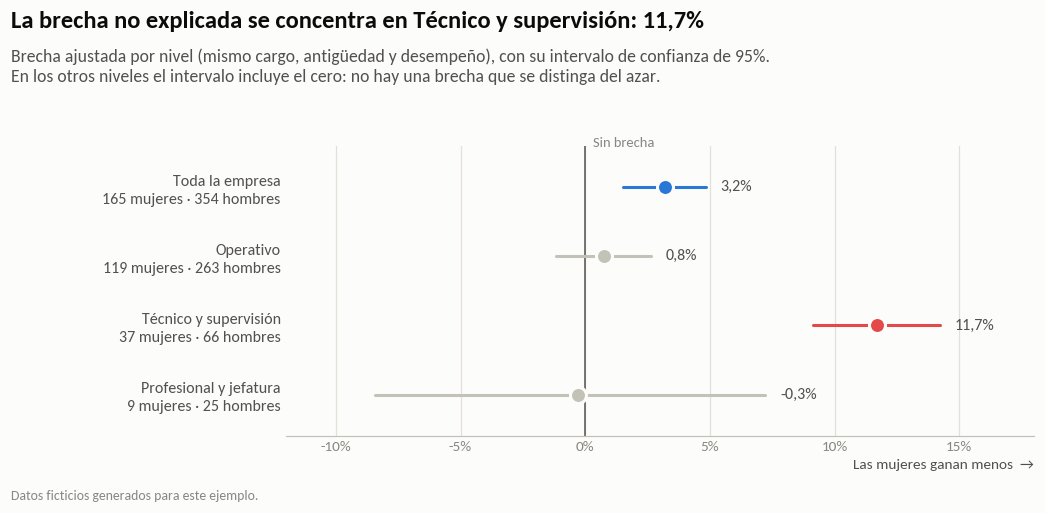

In [13]:
total = escalera.loc[["Mismo cargo, antigüedad y desempeño"]].rename(index=lambda _: "Toda la empresa")
total["mujeres"], total["hombres"] = muestra["mujer"].sum(), (1 - muestra["mujer"]).sum()
filas = pd.concat([total, por_nivel])
colores = [g.AZUL] + [g.ROJO if (n == "Técnico y supervisión") else g.GRIS for n in por_nivel.index]
nivel_top = por_nivel["brecha"].idxmax()

fig, ax = g.figura(alto=4.8, ejes=(0.27, 0.15, 0.68, 0.55))
g.encabezado(fig, f"La brecha no explicada se concentra en {nivel_top}: {g.porcentaje(por_nivel.loc[nivel_top, 'brecha'], 1)}",
             "Brecha ajustada por nivel (mismo cargo, antigüedad y desempeño), con su intervalo de confianza de 95%.\n"
             "En los otros niveles el intervalo incluye el cero: no hay una brecha que se distinga del azar.")
posiciones = np.arange(len(filas))[::-1]
ax.axvline(0, color=g.TINTA_2, linewidth=1, zorder=1)
for y_pos, (nombre, fila), color in zip(posiciones, filas.iterrows(), colores):
    ax.plot([fila["ic95_desde"], fila["ic95_hasta"]], [y_pos, y_pos], color=color, linewidth=2,
            solid_capstyle="round", zorder=2)
    ax.scatter(fila["brecha"], y_pos, s=110, color=color, edgecolors=g.SUPERFICIE, linewidths=2, zorder=3)
    ax.text(fila["ic95_hasta"] + 0.006, y_pos, g.porcentaje(fila["brecha"], 1), va="center", fontsize=10.5, color=g.TINTA_2)
ax.set_yticks(posiciones)
ax.set_yticklabels([f"{n}\n{int(f['mujeres'])} mujeres · {int(f['hombres'])} hombres" for n, f in filas.iterrows()],
                   fontsize=10.5, linespacing=1.4)
ax.set_ylim(-0.6, len(filas) - 0.4)
ax.set_xlim(-0.12, 0.18)
marcas = np.arange(-0.10, 0.16, 0.05)
ax.set_xticks(marcas)
ax.set_xticklabels([g.porcentaje(m) for m in marcas])
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.text(0.003, len(filas) - 0.45, "Sin brecha", fontsize=9.5, color=g.TENUE, va="bottom", ha="left")
ax.set_xlabel("Las mujeres ganan menos  →", color=g.TINTA_2, fontsize=10, loc="right")
g.pie(fig)
g.guardar(fig, IMG / "02_brecha_por_nivel.png")

## 6. Compa-ratio: ¿quién está fuera de su banda?

**Compa-ratio** = haber básico / punto medio de la banda del cargo. Un compa-ratio de 1 es el punto medio; las bandas van de 85% a 115% del punto medio en el nivel operativo, de 80% a 120% en técnico y supervisión, y de 75% a 125% en profesional y jefatura.

Quien gana menos que el mínimo de su banda o más que el máximo está **fuera de política**.

In [14]:
datos["compa_ratio"] = datos["haber_basico_bs"] / datos["punto_medio_bs"]
datos["posicion_banda"] = np.select(
    [datos["haber_basico_bs"] < datos["minimo_bs"], datos["haber_basico_bs"] > datos["maximo_bs"]],
    ["Debajo del mínimo", "Encima del máximo"], default="Dentro de la banda")
POSICIONES = ["Debajo del mínimo", "Dentro de la banda", "Encima del máximo"]

debajo = (datos["posicion_banda"] == "Debajo del mínimo").sum()
encima = (datos["posicion_banda"] == "Encima del máximo").sum()
print(f"Debajo del mínimo: {debajo} personas ({g.porcentaje(debajo / len(datos), 1)})")
print(f"Encima del máximo: {encima} personas ({g.porcentaje(encima / len(datos), 1)})")
pd.crosstab(datos["nivel"], datos["posicion_banda"], margins=True, margins_name="Total").reindex(
    index=NIVELES + ["Total"], columns=POSICIONES + ["Total"])

Debajo del mínimo: 33 personas (6,3%)
Encima del máximo: 16 personas (3,1%)


posicion_banda,Debajo del mínimo,Dentro de la banda,Encima del máximo,Total
nivel,,,,
Operativo,24,342,16,382
Técnico y supervisión,9,94,0,103
Profesional y jefatura,0,35,0,35
Total,33,471,16,520


In [15]:
fuera = datos[datos["posicion_banda"] != "Dentro de la banda"]
por_cargo = (pd.crosstab(fuera["cargo"], fuera["posicion_banda"])
             .join(datos.groupby("cargo")["compa_ratio"].median().rename("compa_ratio_mediano")))
por_cargo.sort_values(["Debajo del mínimo", "Encima del máximo"], ascending=False).head(8)

,Debajo del mínimo,Encima del máximo,compa_ratio_mediano
cargo,,,
Operario de línea,7,4,"0,96"
Chofer repartidor,6,0,"0,93"
Analista de laboratorio,4,0,"0,92"
Auxiliar de almacén,3,2,"0,98"
Operador de llenadora,3,2,"0,93"
Asistente contable,2,0,"0,89"
Ayudante de reparto,1,2,"1,00"
Inspector de calidad,1,1,"0,98"


In [16]:
antiguedad_mediana = datos.groupby("posicion_banda")["antiguedad"].median().reindex(POSICIONES)
print("Antigüedad mediana (años):", " | ".join(f"{p}: {g.miles(v, 1)}" for p, v in antiguedad_mediana.items()))
por_genero_banda = pd.crosstab(datos["genero"], datos["posicion_banda"], normalize="index").reindex(columns=POSICIONES)
por_genero_banda.apply(lambda columna: columna.map(lambda v: g.porcentaje(v, 1)))

Antigüedad mediana (años): Debajo del mínimo: 1,8 | Dentro de la banda: 3,3 | Encima del máximo: 10,1


posicion_banda,Debajo del mínimo,Dentro de la banda,Encima del máximo
genero,,,
Hombre,"4,2%","92,7%","3,1%"
Mujer,"10,9%","86,1%","3,0%"


Quienes están debajo del mínimo se concentran en dos grupos: operativos de los cargos donde el mercado subió (ver la sección 7) y mujeres de Técnico y supervisión, el mismo nivel donde está la brecha. Por eso la proporción de mujeres debajo del mínimo es más del doble que la de hombres. Quienes están encima del máximo son operativos con muchos años en la empresa: sueldos que siguieron subiendo cuando ya estaban en el tope.

PosixPath('img/03_compa_ratio.png')

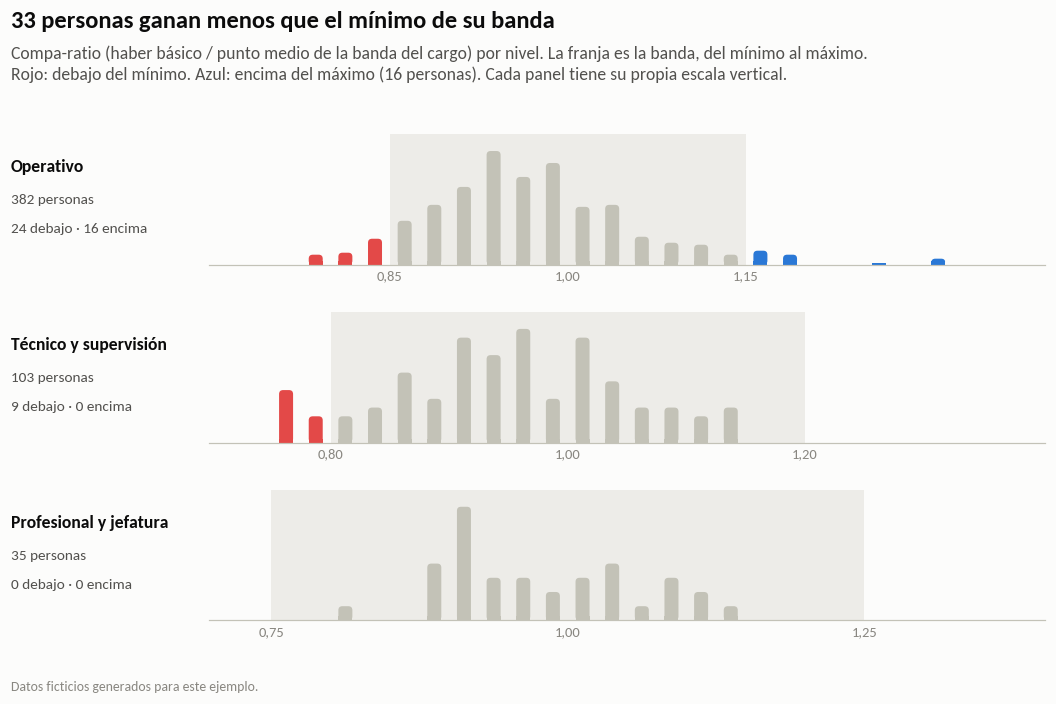

In [17]:
ANCHO = 0.025
bordes = np.round(np.arange(0.70, 1.40 + ANCHO / 2, ANCHO), 3)
AMPLITUD = {"Operativo": 0.15, "Técnico y supervisión": 0.20, "Profesional y jefatura": 0.25}
COLOR_POSICION = {"Debajo del mínimo": g.ROJO, "Dentro de la banda": g.GRIS, "Encima del máximo": g.AZUL}

def posicion_en_eje(valor):
    """Las columnas están en 0, 1, 2...; el borde izquierdo de la columna i está en i - 0,5."""
    return (valor - bordes[0]) / ANCHO - 0.5

fig = plt.figure(figsize=(10, 6.6))
# encabezado a mano: la figura es más alta que las otras y así título y subtítulo quedan a la misma distancia
fig.text(0.02, 0.965, f"{debajo} personas ganan menos que el mínimo de su banda",
         fontsize=16, fontweight="bold", color=g.TINTA, va="top")
fig.text(0.02, 0.918, "Compa-ratio (haber básico / punto medio de la banda del cargo) por nivel. La franja es la banda, del mínimo al máximo.\n"
                      f"Rojo: debajo del mínimo. Azul: encima del máximo ({encima} personas). Cada panel tiene su propia escala vertical.",
         fontsize=11.5, color=g.TINTA_2, va="top", linespacing=1.35)
for i, nivel in enumerate(NIVELES):
    grupo = datos[datos["nivel"] == nivel]
    base_panel = 0.615 - i * 0.245
    ax = fig.add_axes((0.20, base_panel, 0.76, 0.18))
    clase = pd.cut(grupo["compa_ratio"].clip(bordes[0], bordes[-1] - 1e-9), bordes, right=False)
    conteo = pd.crosstab(clase, grupo["posicion_banda"]).reindex(columns=POSICIONES, fill_value=0)
    conteo = conteo.reindex(pd.IntervalIndex.from_breaks(bordes, closed="left"), fill_value=0)
    # cada columna tiene una sola posición, porque los bordes coinciden con el mínimo y el máximo de la banda
    assert (conteo.gt(0).sum(axis=1) <= 1).all()
    colores = [COLOR_POSICION[conteo.columns[fila.argmax()]] for fila in conteo.values]
    g.columnas(ax, [""] * len(conteo), conteo.sum(axis=1).values, colores, grosor_px=14,
               y_max=conteo.sum(axis=1).max() * 1.15)
    a = AMPLITUD[nivel]
    ax.axvspan(posicion_en_eje(1 - a), posicion_en_eje(1 + a), color=g.GRILLA, alpha=0.55, zorder=0, linewidth=0)
    marcas = [round(1 - a, 2), 1.0, round(1 + a, 2)]
    ax.set_xticks([posicion_en_eje(m) for m in marcas])
    ax.set_xticklabels([g.miles(m, 2) for m in marcas], fontsize=9.5, color=g.TENUE)
    ax.spines["bottom"].set_color(g.EJE)
    resumen = grupo["posicion_banda"].value_counts()
    fig.text(0.02, base_panel + 0.135, nivel, fontsize=11.5, fontweight="bold", color=g.TINTA, va="center")
    fig.text(0.02, base_panel + 0.09, f"{len(grupo)} personas", fontsize=10, color=g.TINTA_2, va="center")
    fig.text(0.02, base_panel + 0.05,
             f"{resumen.get('Debajo del mínimo', 0)} debajo · {resumen.get('Encima del máximo', 0)} encima",
             fontsize=10, color=g.TINTA_2, va="center")
g.pie(fig)
g.guardar(fig, IMG / "03_compa_ratio.png")

## 7. Compresión salarial: nuevos contra antiguos

Hay **compresión** cuando alguien que acaba de entrar gana igual o más que alguien con años en el mismo cargo. Pasa cuando el mercado sube y la empresa paga más para contratar, pero no ajusta a quienes ya estaban.

Para cada cargo operativo se compara la mediana del haber de los **ingresos del último año** con la de quienes tienen **3 a 5 años**. Se marca compresión si la de los nuevos es igual o mayor, con al menos 4 personas en cada grupo.

In [18]:
MINIMO_GRUPO = 4
filas = []
for cargo, grupo in datos[datos["nivel"] == "Operativo"].groupby("cargo"):
    nuevos = grupo.loc[grupo["antiguedad"] < 1, "haber_basico_bs"]
    antiguos = grupo.loc[(grupo["antiguedad"] >= 3) & (grupo["antiguedad"] < 5), "haber_basico_bs"]
    filas.append({"cargo": cargo, "personas": len(grupo), "nuevos": len(nuevos), "de_3_a_5_anios": len(antiguos),
                  "mediana_nuevos_bs": nuevos.median(), "mediana_3_a_5_bs": antiguos.median()})
compresion = pd.DataFrame(filas).set_index("cargo")
compresion["nuevos_vs_antiguos"] = compresion["mediana_nuevos_bs"] / compresion["mediana_3_a_5_bs"]
alcanza = compresion[["nuevos", "de_3_a_5_anios"]].min(axis=1) >= MINIMO_GRUPO
compresion["compresion"] = np.where(~alcanza, "pocos casos", np.where(compresion["nuevos_vs_antiguos"] >= 1, "Sí", "No"))
cargos_comprimidos = compresion.index[compresion["compresion"] == "Sí"].tolist()
print("Cargos con compresión:", ", ".join(cargos_comprimidos))
compresion.sort_values("nuevos_vs_antiguos", ascending=False)

Cargos con compresión: Chofer repartidor, Operador de llenadora, Operario de línea


,personas,nuevos,de_3_a_5_anios,mediana_nuevos_bs,mediana_3_a_5_bs,nuevos_vs_antiguos,compresion
cargo,,,,,,,
Chofer repartidor,42,4,10,4.722,4.349,"1,09",Sí
Operario de línea,85,18,11,4.269,4.001,"1,07",Sí
Operador de llenadora,43,10,4,4.662,4.370,"1,07",Sí
Auxiliar de almacén,21,8,2,3.470,3.402,"1,02",pocos casos
Auxiliar de producción,43,7,6,3.427,3.458,"0,99",No
Mercaderista,24,8,4,3.235,3.400,"0,95",No
Preventista,36,6,6,3.738,3.958,"0,94",No
Ayudante de reparto,42,7,7,3.205,3.456,"0,93",No
Inspector de calidad,14,4,4,3.809,4.170,"0,91",No


Operario de línea: quien entró en el último año gana 6,7% más que quien tiene 3 a 5 años (medianas)
Operario de línea: mediana del haber por tramo de antigüedad
                mediana_bs  personas
tramo                               
Menos de 1 año       4.269        18
1 a 3 años           3.850        21
3 a 5 años           4.001        11
5 a 10 años          4.276        23
10 años o más        4.608        12


PosixPath('img/04_compresion.png')

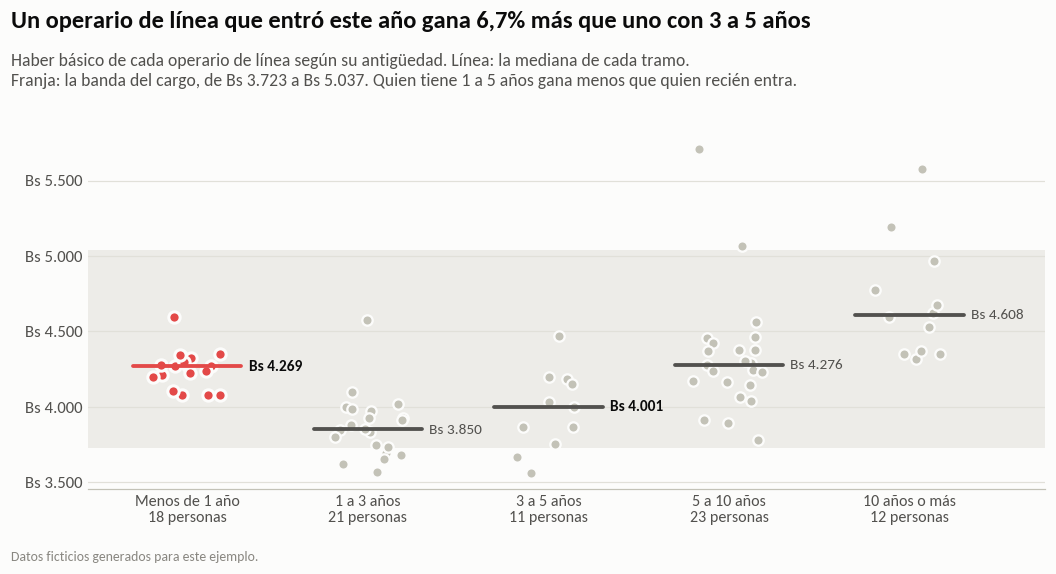

In [19]:
cargo_ejemplo = compresion.loc[cargos_comprimidos, "personas"].idxmax()
grupo = datos[datos["cargo"] == cargo_ejemplo].copy()
banda = bandas.set_index("cargo").loc[cargo_ejemplo]
TRAMOS = ["Menos de 1 año", "1 a 3 años", "3 a 5 años", "5 a 10 años", "10 años o más"]
grupo["tramo"] = pd.cut(grupo["antiguedad"], [0, 1, 3, 5, 10, np.inf], labels=TRAMOS, right=False)
por_tramo = grupo.groupby("tramo", observed=False)["haber_basico_bs"].agg(["median", "count"])
diferencia = compresion.loc[cargo_ejemplo, "nuevos_vs_antiguos"] - 1
print(f"{cargo_ejemplo}: quien entró en el último año gana {g.porcentaje(diferencia, 1)} más que quien tiene 3 a 5 años (medianas)")
print(f"{cargo_ejemplo}: mediana del haber por tramo de antigüedad")
print(por_tramo.rename(columns={"median": "mediana_bs", "count": "personas"}).to_string())

fig, ax = g.figura(alto=5.4, ejes=(0.09, 0.15, 0.87, 0.6))
g.encabezado(fig, f"Un {cargo_ejemplo.lower()} que entró este año gana {g.porcentaje(diferencia, 1)} más que uno con 3 a 5 años",
             f"Haber básico de cada {cargo_ejemplo.lower()} según su antigüedad. Línea: la mediana de cada tramo.\n"
             f"Franja: la banda del cargo, de {g.bs(banda['minimo_bs'])} a {g.bs(banda['maximo_bs'])}. "
             "Quien tiene 1 a 5 años gana menos que quien recién entra.")
ax.axhspan(banda["minimo_bs"], banda["maximo_bs"], color=g.GRILLA, alpha=0.55, zorder=0, linewidth=0)
dispersion = np.random.default_rng(1)   # solo para separar los puntos en horizontal
for i, tramo in enumerate(TRAMOS):
    sueldos = grupo.loc[grupo["tramo"] == tramo, "haber_basico_bs"]
    reciente = i == 0
    ax.scatter(i + dispersion.uniform(-0.2, 0.2, len(sueldos)), sueldos, s=55 if reciente else 46,
               color=g.ROJO if reciente else g.GRIS, edgecolors=g.SUPERFICIE, linewidths=2 if reciente else 1.5, zorder=2)
    mediana = por_tramo.loc[tramo, "median"]
    ax.plot([i - 0.3, i + 0.3], [mediana] * 2, color=g.ROJO if reciente else g.TINTA_2, linewidth=2.5,
            solid_capstyle="round", zorder=3)
    ax.text(i + 0.34, mediana, g.bs(mediana), va="center", fontsize=10, color=g.TINTA if i in (0, 2) else g.TINTA_2,
            fontweight="bold" if i in (0, 2) else "normal")
ax.set_xticks(range(len(TRAMOS)))
ax.set_xticklabels([f"{t}\n{int(por_tramo.loc[t, 'count'])} personas" for t in TRAMOS], color=g.TINTA_2, fontsize=10.5)
ax.set_xlim(-0.55, len(TRAMOS) - 0.25)
ax.yaxis.set_major_formatter(lambda v, _: g.bs(v))
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.spines["bottom"].set_color(g.EJE)
g.pie(fig)
g.guardar(fig, IMG / "04_compresion.png")

## 8. ¿Cuánto cuesta cerrar las brechas?

**Costo de subir Bs 1 el haber mensual** = 12 × (1 + 0,1671 + 2/12) = **Bs 16,01 al año**:

- 12 meses de haber;
- 16,71% de aportes patronales sobre esos 12 meses (salud 10%, riesgo profesional 1,71%, aporte solidario 3%, vivienda 2%);
- 2/12 por mes de provisiones: aguinaldo (un sueldo al año) e indemnización (un sueldo por año de servicio). Suman 2 sueldos más al año.

No incluye el efecto en las horas extra, que se pagan sobre el haber básico; el bono de antigüedad no cambia, porque se calcula sobre el salario mínimo.

Tres ajustes, cada uno con su regla:

- **(a) Mínimo de la banda**: subir a todos los que están debajo del mínimo hasta el mínimo.
- **(b) Brecha no explicada, caso por caso**: en el nivel donde la brecha es distinta de cero, el modelo por nivel (sección 5) estima cuánto ganaría un hombre con el mismo cargo, antigüedad y desempeño de cada mujer. Si ella gana menos, se la lleva a ese valor.
- **(c) Compresión**: en los cargos con compresión, subir a quien tiene 1 año o más y gana menos que la mediana de los ingresos recientes hasta esa mediana.

Una persona puede tener más de un motivo. El costo de los tres juntos toma, para cada persona, el ajuste más alto: no suma dos veces.

In [20]:
APORTES_PATRONALES = 0.1671
PROVISIONES = 2 / 12   # aguinaldo + indemnización
COSTO_ANUAL_POR_BS = 12 * (1 + APORTES_PATRONALES + PROVISIONES)
print(f"Subir Bs 1 el haber mensual cuesta Bs {g.miles(COSTO_ANUAL_POR_BS, 2)} al año")

# Todos los ajustes se redondean a bolivianos enteros

# (a) llevar al mínimo de la banda
datos["ajuste_minimo"] = (datos["minimo_bs"] - datos["haber_basico_bs"]).clip(lower=0)

# (b) llevar a cada mujer del nivel con brecha a lo que el modelo predice para un hombre con su perfil
niveles_con_brecha = por_nivel.index[por_nivel["ic95_desde"] > 0].tolist()
esperado = np.exp(modelo_nivel.predict(muestra.assign(mujer=0))).round()
datos["haber_esperado_bs"] = esperado.reindex(datos.index)
corresponde = (datos["mujer"] == 1) & datos["nivel"].isin(niveles_con_brecha)
datos["ajuste_genero"] = (datos["haber_esperado_bs"] - datos["haber_basico_bs"]).clip(lower=0).where(corresponde, 0).fillna(0)

# (c) compresión: quien tiene 1 año o más no gana menos que la mediana de los ingresos recientes de su cargo
objetivo = datos["cargo"].map(compresion.loc[cargos_comprimidos, "mediana_nuevos_bs"]).round()
corresponde = datos["cargo"].isin(cargos_comprimidos) & (datos["antiguedad"] >= 1)
datos["ajuste_compresion"] = (objetivo - datos["haber_basico_bs"]).clip(lower=0).where(corresponde, 0).fillna(0)

AJUSTES = {"ajuste_minimo": "(a) Llevar al mínimo de la banda",
           "ajuste_genero": "(b) Cerrar la brecha no explicada",
           "ajuste_compresion": "(c) Corregir la compresión"}
datos["ajuste_total"] = datos[list(AJUSTES)].max(axis=1)
costos = pd.DataFrame({
    "personas": [(datos[c] > 0).sum() for c in [*AJUSTES, "ajuste_total"]],
    "ajuste_mensual_bs": [datos[c].sum() for c in [*AJUSTES, "ajuste_total"]],
}, index=[*AJUSTES.values(), "Los tres juntos (sin contar dos veces)"])
costos["costo_anual_bs"] = costos["ajuste_mensual_bs"] * COSTO_ANUAL_POR_BS
planilla_anual = datos["haber_basico_bs"].sum() * COSTO_ANUAL_POR_BS
costos["% del costo anual de haberes"] = (costos["costo_anual_bs"] / planilla_anual).map(lambda v: g.porcentaje(v, 1))
print("Nivel con brecha distinta de cero:", ", ".join(niveles_con_brecha))
print(f"Costo anual de los haberes básicos (con aportes y provisiones): {g.bs(planilla_anual)}")
costos

Subir Bs 1 el haber mensual cuesta Bs 16,01 al año
Nivel con brecha distinta de cero: Técnico y supervisión
Costo anual de los haberes básicos (con aportes y provisiones): Bs 43.349.780


,personas,ajuste_mensual_bs,costo_anual_bs,% del costo anual de haberes
(a) Llevar al mínimo de la banda,33,4.888,78.233,"0,2%"
(b) Cerrar la brecha no explicada,37,28.493,456.036,"1,1%"
(c) Corregir la compresión,92,33.455,535.454,"1,2%"
Los tres juntos (sin contar dos veces),137,62.996,1.008.264,"2,3%"


In [21]:
genero = datos[datos["ajuste_genero"] > 0]
mujeres_nivel = datos[(datos["mujer"] == 1) & datos["nivel"].isin(niveles_con_brecha)]
brecha_nivel = por_nivel.loc[nivel_top, "brecha"]
cuantas = f"Las {len(genero)}" if len(genero) == len(mujeres_nivel) else f"{len(genero)} de las {len(mujeres_nivel)}"
print(f"(b) {cuantas} mujeres de {', '.join(niveles_con_brecha)} ganan menos de lo esperado para un hombre con su perfil.")
print(f"    Ajuste mediano: {g.bs(genero['ajuste_genero'].median())} por mes "
      f"({g.porcentaje((genero['ajuste_genero'] / genero['haber_basico_bs']).median(), 1)} de su haber).")
print(f"    Una brecha de {g.porcentaje(brecha_nivel, 1)} sobre el haber del hombre equivale a "
      f"{g.porcentaje(1 / (1 - brecha_nivel) - 1, 1)} sobre el haber de la mujer.")

# Sensibilidad: el mismo criterio aplicado a todas las mujeres, aunque en los otros niveles no haya brecha
todas = (datos["haber_esperado_bs"] - datos["haber_basico_bs"]).clip(lower=0).where(datos["mujer"] == 1, 0).fillna(0)
print(f"Si se aplicara a las mujeres de todos los niveles: {g.bs(todas.sum() * COSTO_ANUAL_POR_BS)} al año "
      f"({(todas > 0).sum()} mujeres). En los otros niveles esas diferencias son la variación normal que también tienen los hombres.")

(b) Las 37 mujeres de Técnico y supervisión ganan menos de lo esperado para un hombre con su perfil.
    Ajuste mediano: Bs 765 por mes (13,1% de su haber).
    Una brecha de 11,7% sobre el haber del hombre equivale a 13,3% sobre el haber de la mujer.
Si se aplicara a las mujeres de todos los niveles: Bs 695.986 al año (111 mujeres). En los otros niveles esas diferencias son la variación normal que también tienen los hombres.


PosixPath('img/05_costo_de_cerrar_brechas.png')

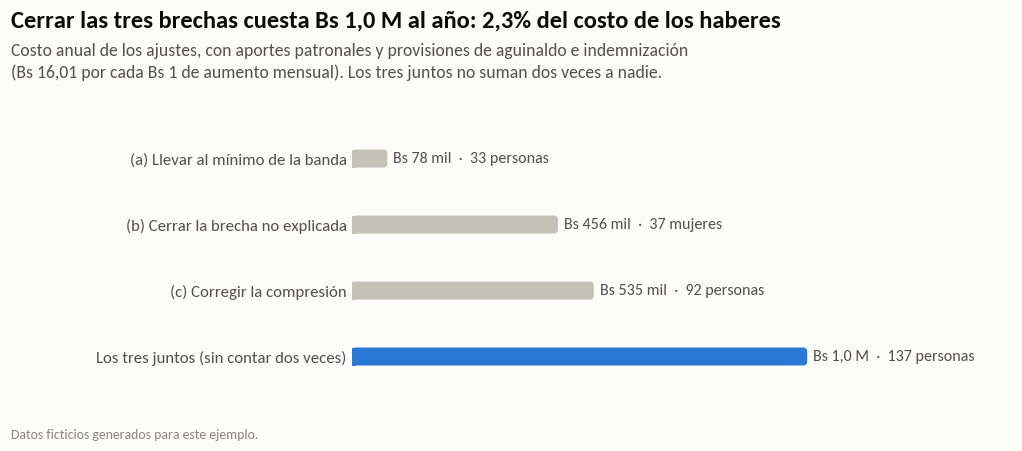

In [22]:
tabla = costos
total_anual = costos["costo_anual_bs"].iloc[3]
fig, ax = g.figura(alto=4.2, ejes=(0.33, 0.12, 0.6, 0.6))
g.encabezado(fig, f"Cerrar las tres brechas cuesta {g.bs_compacto(total_anual)} al año: "
                  f"{g.porcentaje(total_anual / planilla_anual, 1)} del costo de los haberes",
             "Costo anual de los ajustes, con aportes patronales y provisiones de aguinaldo e indemnización\n"
             f"(Bs {g.miles(COSTO_ANUAL_POR_BS, 2)} por cada Bs 1 de aumento mensual). Los tres juntos no suman dos veces a nadie.")
g.barras_horizontales(ax, tabla.index, tabla["costo_anual_bs"].values, [g.GRIS, g.GRIS, g.GRIS, g.AZUL],
                      textos=[f"{g.bs_compacto(v)}  ·  {p} {'mujeres' if 'brecha' in n else 'personas'}"
                              for n, v, p in zip(tabla.index, tabla["costo_anual_bs"], tabla["personas"])],
                      x_max=tabla["costo_anual_bs"].max() * 1.45, grosor_px=18)
g.pie(fig)
g.guardar(fig, IMG / "05_costo_de_cerrar_brechas.png")

## 9. Lista priorizada de ajustes

Una fila por persona con al menos un ajuste. Si tiene más de un motivo, el ajuste sugerido es el más alto. El orden de prioridad:

1. **Brecha no explicada** en el nivel donde es distinta de cero.
2. **Debajo del mínimo** de la banda.
3. **Compresión**.

Dentro de cada prioridad, primero los ajustes más grandes en % del haber. La lista es una agenda de revisión, no una decisión automática.

In [23]:
MOTIVOS = {"ajuste_genero": "Brecha no explicada", "ajuste_minimo": "Debajo del mínimo", "ajuste_compresion": "Compresión"}
lista = datos[datos["ajuste_total"] > 0].copy()
lista["motivo"] = lista.apply(lambda f: " + ".join(m for c, m in MOTIVOS.items() if f[c] > 0), axis=1)
lista["prioridad"] = np.select([lista["ajuste_genero"] > 0, lista["ajuste_minimo"] > 0], [1, 2], default=3)
lista["ajuste_mensual_bs"] = lista["ajuste_total"].round().astype(int)
lista["ajuste_pct"] = (lista["ajuste_mensual_bs"] / lista["haber_basico_bs"] * 100).round(1)
lista["haber_sugerido_bs"] = lista["haber_basico_bs"] + lista["ajuste_mensual_bs"]
lista["costo_anual_bs"] = (lista["ajuste_mensual_bs"] * COSTO_ANUAL_POR_BS).round().astype(int)
columnas = ["prioridad", "id_colaborador", "area", "cargo", "nivel", "genero", "motivo",
            "haber_basico_bs", "haber_sugerido_bs", "ajuste_mensual_bs", "ajuste_pct", "costo_anual_bs"]
lista = lista.sort_values(["prioridad", "ajuste_pct"], ascending=[True, False])[columnas]
lista.to_csv(RESULTADOS / "ajustes_sugeridos.csv", index=False)
print(f"{len(lista)} personas en resultados/ajustes_sugeridos.csv")
por_prioridad = lista.groupby("prioridad").agg(personas=("id_colaborador", "count"), ajuste_mensual_bs=("ajuste_mensual_bs", "sum"))
por_prioridad["ajuste_mensual_bs"] = por_prioridad["ajuste_mensual_bs"].astype(float)
por_prioridad["costo_anual_bs"] = por_prioridad["ajuste_mensual_bs"] * COSTO_ANUAL_POR_BS
por_prioridad

137 personas en resultados/ajustes_sugeridos.csv


,personas,ajuste_mensual_bs,costo_anual_bs
prioridad,,,
1,37,28.493,456.036
2,24,11.905,190.542
3,76,22.598,361.686


In [24]:
lista.head(10).reset_index(drop=True)

,prioridad,id_colaborador,area,cargo,nivel,genero,motivo,haber_basico_bs,haber_sugerido_bs,ajuste_mensual_bs,ajuste_pct,costo_anual_bs
0,1,C0138,Logística y Distribución,Encargado de almacén,Técnico y supervisión,Mujer,Brecha no explicada + Debajo del mínimo,5056,6361,1305,"25,80",20887
1,1,C0356,Calidad,Analista de laboratorio,Técnico y supervisión,Mujer,Brecha no explicada + Debajo del mínimo,5059,6357,1298,"25,70",20775
2,1,C0411,Administración y Finanzas,Asistente contable,Técnico y supervisión,Mujer,Brecha no explicada + Debajo del mínimo,4737,5777,1040,"22,00",16645
3,1,C0316,Ventas,Supervisor de ventas,Técnico y supervisión,Mujer,Brecha no explicada + Debajo del mínimo,6050,7327,1277,"21,10",20439
4,1,C0355,Calidad,Analista de laboratorio,Técnico y supervisión,Mujer,Brecha no explicada + Debajo del mínimo,5156,6219,1063,"20,60",17014
5,1,C0516,Producción,Supervisor de turno,Técnico y supervisión,Mujer,Brecha no explicada + Debajo del mínimo,5877,7012,1135,"19,30",18166
6,1,C0327,Ventas,Supervisor de ventas,Técnico y supervisión,Mujer,Brecha no explicada,6320,7476,1156,"18,30",18502
7,1,C0344,Administración y Finanzas,Asistente de RRHH,Técnico y supervisión,Mujer,Brecha no explicada,5025,5943,918,"18,30",14693
8,1,C0078,Administración y Finanzas,Asistente contable,Técnico y supervisión,Mujer,Brecha no explicada,5613,6624,1011,"18,00",16181
9,1,C0454,Administración y Finanzas,Asistente contable,Técnico y supervisión,Mujer,Brecha no explicada + Debajo del mínimo,4861,5731,870,"17,90",13925


## 10. Resumen y qué hacer primero

In [25]:
prioridad_1 = lista[lista["prioridad"] == 1]
cifras = {
    "Personas": f"{len(datos)} ({datos['mujer'].sum()} mujeres, {g.porcentaje(datos['mujer'].mean(), 1)})",
    "Brecha bruta en el promedio": g.porcentaje(brecha_media, 1),
    "Brecha bruta en la mediana": g.porcentaje(brecha_mediana, 1),
    "Brecha en el mismo cargo": g.porcentaje(escalera.loc["Mismo cargo", "brecha"], 1),
    "Brecha ajustada": g.porcentaje(brecha_ajustada["brecha"], 1),
    "IC 95% de la brecha ajustada": f"{g.porcentaje(brecha_ajustada['ic95_desde'], 1)} a {g.porcentaje(brecha_ajustada['ic95_hasta'], 1)}",
    "Parte explicada (Oaxaca-Blinder)": g.porcentaje(explicada),
    "Parte explicada por el cargo": g.porcentaje(partes["Explicada por el cargo"] / brecha_log),
    "Nivel con brecha": nivel_top,
    "Brecha ajustada en ese nivel": g.porcentaje(por_nivel.loc[nivel_top, "brecha"], 1),
    "IC 95% en ese nivel": f"{g.porcentaje(por_nivel.loc[nivel_top, 'ic95_desde'], 1)} a {g.porcentaje(por_nivel.loc[nivel_top, 'ic95_hasta'], 1)}",
    "Debajo del mínimo de su banda": f"{debajo} ({g.porcentaje(debajo / len(datos), 1)})",
    "Encima del máximo de su banda": f"{encima} ({g.porcentaje(encima / len(datos), 1)})",
    "Cargos con compresión": ", ".join(cargos_comprimidos),
    "Costo anual por Bs 1 de aumento mensual": f"Bs {g.miles(COSTO_ANUAL_POR_BS, 2)}",
    "Costo (a) mínimo de la banda": f"{g.bs(costos['costo_anual_bs'].iloc[0])} al año ({costos['personas'].iloc[0]} personas)",
    "Costo (b) brecha no explicada": f"{g.bs(costos['costo_anual_bs'].iloc[1])} al año ({costos['personas'].iloc[1]} mujeres)",
    "Costo (c) compresión": f"{g.bs(costos['costo_anual_bs'].iloc[2])} al año ({costos['personas'].iloc[2]} personas)",
    "Costo de los tres juntos": f"{g.bs(total_anual)} al año ({costos['personas'].iloc[3]} personas, "
                                f"{g.porcentaje(total_anual / planilla_anual, 1)} del costo de los haberes)",
    "Prioridad 1": f"{len(prioridad_1)} mujeres, {g.bs(prioridad_1['ajuste_mensual_bs'].sum())} por mes, "
                   f"{g.bs(prioridad_1['ajuste_mensual_bs'].sum() * COSTO_ANUAL_POR_BS)} al año",
}
for clave, valor in cifras.items():
    print(f"{clave}: {valor}")

Personas: 520 (165 mujeres, 31,7%)
Brecha bruta en el promedio: 13,4%
Brecha bruta en la mediana: 7,4%
Brecha en el mismo cargo: 4,9%
Brecha ajustada: 3,2%
IC 95% de la brecha ajustada: 1,5% a 4,8%
Parte explicada (Oaxaca-Blinder): 70%
Parte explicada por el cargo: 58%
Nivel con brecha: Técnico y supervisión
Brecha ajustada en ese nivel: 11,7%
IC 95% en ese nivel: 9,1% a 14,2%
Debajo del mínimo de su banda: 33 (6,3%)
Encima del máximo de su banda: 16 (3,1%)
Cargos con compresión: Chofer repartidor, Operador de llenadora, Operario de línea
Costo anual por Bs 1 de aumento mensual: Bs 16,01
Costo (a) mínimo de la banda: Bs 78.233 al año (33 personas)
Costo (b) brecha no explicada: Bs 456.036 al año (37 mujeres)
Costo (c) compresión: Bs 535.454 al año (92 personas)
Costo de los tres juntos: Bs 1.008.264 al año (137 personas, 2,3% del costo de los haberes)
Prioridad 1: 37 mujeres, Bs 28.493 por mes, Bs 456.036 al año


In [26]:
debajo_en_nivel = prioridad_1["motivo"].str.contains("mínimo").sum()
print(f"1) Revisar caso por caso los sueldos de las mujeres de {nivel_top}.")
print(f"   {cuantas} ganan menos de lo que el modelo predice para un hombre con su mismo")
print(f"   cargo, antigüedad y desempeño, y {debajo_en_nivel} además están debajo del mínimo de su banda.")
print(f"   Cerrar esa brecha cuesta {g.bs(prioridad_1['ajuste_mensual_bs'].sum() * COSTO_ANUAL_POR_BS)} al año "
      f"({g.bs(prioridad_1['ajuste_mensual_bs'].sum())} por mes).")
print("   En cada caso, primero buscar una razón que los datos no ven (experiencia previa, formación); si no la hay, ajustar.")
print()
print(f"2) Llevar al mínimo de su banda a las {debajo} personas que están debajo ({g.bs(costos['costo_anual_bs'].iloc[0])} al año)")
print("   y fijar una regla simple: nadie gana menos que el mínimo de su banda, tampoco al ascender.")
print()
comprimidos = lista[lista["motivo"].str.contains("Compresión")]
print(f"3) Corregir la compresión en {', '.join(cargos_comprimidos)}: {len(comprimidos)} personas, "
      f"{g.bs(costos['costo_anual_bs'].iloc[2])} al año.")
print("   Se puede escalonar, por ejemplo con el incremento de mayo. Es un riesgo de rotación: quien tiene años")
print("   en el cargo ve que un recién llegado gana más.")

1) Revisar caso por caso los sueldos de las mujeres de Técnico y supervisión.
   Las 37 ganan menos de lo que el modelo predice para un hombre con su mismo
   cargo, antigüedad y desempeño, y 9 además están debajo del mínimo de su banda.
   Cerrar esa brecha cuesta Bs 456.036 al año (Bs 28.493 por mes).
   En cada caso, primero buscar una razón que los datos no ven (experiencia previa, formación); si no la hay, ajustar.

2) Llevar al mínimo de su banda a las 33 personas que están debajo (Bs 78.233 al año)
   y fijar una regla simple: nadie gana menos que el mínimo de su banda, tampoco al ascender.

3) Corregir la compresión en Chofer repartidor, Operador de llenadora, Operario de línea: 92 personas, Bs 535.454 al año.
   Se puede escalonar, por ejemplo con el incremento de mayo. Es un riesgo de rotación: quien tiene años
   en el cargo ve que un recién llegado gana más.


## 11. Límites

- **Los datos son ficticios.** Con datos reales hay que revisar las bandas y la regla de cada ajuste junto con Finanzas y la gerencia.
- **Una brecha no explicada no prueba discriminación.** El modelo no ve experiencia previa, formación, turnos ni la negociación al ingresar. Si alguna de esas variables explica la diferencia, hay que sumarla al modelo. Por eso la lista es para revisar caso por caso.
- **Pocos casos en algunos grupos.** Profesional y jefatura tiene pocas mujeres: su intervalo es ancho y no permite concluir que no hay brecha. Mantenimiento tiene muy pocas mujeres para estimar su brecha.
- **El costo es una foto.** No incluye el efecto en horas extra ni en el incremento salarial de mayo, que se aplica sobre el haber ajustado.